# Responsible Innovation in National AI Policies
### Adoption, legal status, governance capacity and the actualization of responsible-innovation commitments

**Target journal:** *Technological Forecasting and Social Change* (Elsevier)
**Anchor paper:** *Responsible AI for responsible innovation in Chinese manufacturing: From the affordance–actualization theory* (2025), DOI: 10.1016/j.techfore.2025.124349

**Theoretical lens.** Responsible innovation (RI) is operationalised with the four dimensions of Stilgoe, Owen & Macnaghten (2013): *anticipation, reflexivity, inclusion, responsiveness*. Following the affordance–actualization perspective of the anchor paper, lifted from the firm to the state level, a national AI **strategy articulates** the affordances of AI, while **binding instruments, dedicated institutions, obligations and resourced targets actualize** them.

| RQ | Question | Main exhibit |
|---|---|---|
| **RQ1** | Which RI dimensions do national AI policy instruments articulate, and does the RI profile shift from ethics-oriented reflexivity in non-binding instruments to risk- and accountability-oriented responsiveness in binding ones? | Figure 1 + Table 1 |
| **RQ2** | Is government effectiveness associated with national AI strategy adoption, and is this association conditional on income level? | Figure 2 + Table 2 |
| **RQ3** | Among countries with AI policies, does governance capacity predict the actualization of strategic commitments into binding instruments, or are the two decoupled? | Figure 3 + Table 3 |
| **RQ4** | How have legal status and RI profile changed between the pre-generative-AI (2017–2022) and generative-AI (2023+) periods? | Figure 4 + Table 4 |

**Methodology (one step per notebook section)**
1. Environment set-up and data discovery (Kaggle input or local files).
2. Data audit of the three source files.
3. Sample construction: restrict to country-level instruments; build a 197-country frame.
4. Link the World Bank WGI (Government Effectiveness, Regulatory Quality, income group) by harmonised country names.
5. Build country-level policy indicators, including attribution of the EU AI Act to the 27 EU member states.
6. Define a transparent RI codebook (Stilgoe dimensions → sub-themes → indicator terms, plus actualization markers).
7. Apply the codebook to every policy summary; export a coding sheet and a stratified validation sample for manual verification (optional hook to load human-verified codes and compute Cohen's κ).
8. **RQ1**: binding vs non-binding RI profiles (Fisher exact tests, odds ratios, Benjamini–Hochberg correction).
9. **RQ2**: strategy adoption vs Government Effectiveness, overall and within income groups (Mann–Whitney, Cliff's δ, logistic regression with GE × income interaction).
10. **RQ3**: two-stage "articulation → actualization" analysis (Kruskal–Wallis, Mann–Whitney, Firth penalised logistic regression) and implementation concreteness of strategies vs GE (Spearman).
11. **RQ4**: period comparison of legal status, instrument types and RI profile (Fisher exact tests, BH correction).
12. Robustness checks (verified/high-confidence records, pre-period GE, Regulatory Quality, EU exclusion/adjustment).
13. Summary of key findings and export of all figures (PDF + PNG) and tables (CSV) into a zipped folder.

No machine learning is used: everything is descriptive statistics, rule-based content coding, cross-tabulations and classical tests.

## Step 1 · Environment set-up
**What this cell does:** imports the libraries, defines the output folders (`/kaggle/working/outputs` on Kaggle, `./outputs` elsewhere), sets a consistent publication style for all figures (colour-blind-checked palette, thin marks, recessive grid) and defines two helpers that both *display* and *save* every exhibit: figures as PDF (vector, for submission) and PNG (300 dpi), tables as CSV.
**Methodological step:** reproducibility infrastructure used by every RQ.

In [1]:
import os, re, glob, json, zipfile, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.transforms as mtrans
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
SEED = 2026
rng = np.random.default_rng(SEED)

# ---- output folders --------------------------------------------------------
OUT = Path("/kaggle/working/outputs") if Path("/kaggle/working").exists() else Path("outputs")
FIG, TAB = OUT / "figures", OUT / "tables"
for d in (FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

# ---- publication style -------------------------------------------------------
COL = {  # validated categorical slots (light mode) + neutral inks
    "binding": "#2a78d6",      # slot 1 blue
    "nonbinding": "#eb6834",   # slot 2 orange
    "post": "#1baf7a",         # slot 3 aqua
    "pre": "#8f8e88",          # neutral gray
    "none": "#b5b4ae",         # neutral gray (no instrument)
    "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#8a8984", "grid": "#e6e5e0",
}
INCOME_SEQ = ["#9ec5f2", "#4f93e0", "#1d5aa8"]   # sequential blue: low -> high income
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.labelcolor": COL["ink2"], "axes.edgecolor": COL["muted"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": COL["grid"], "grid.linewidth": 0.6,
    "xtick.color": COL["ink2"], "ytick.color": COL["ink2"], "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5, "text.color": COL["ink"],
    "lines.linewidth": 2, "axes.axisbelow": True,
})

def save_fig(fig, name):
    # Save a figure as vector PDF + 300-dpi PNG and display it inline.
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()
    print(f"saved -> {FIG / (name + '.pdf')}")

def save_table(df, name, index=False, show=True):
    # Save a table as CSV and display it inline.
    df.to_csv(TAB / f"{name}.csv", index=index)
    if show:
        display(df)
    print(f"saved -> {TAB / (name + '.csv')}")

def fmt_p(p):
    if pd.isna(p): return "n/a"
    return "<0.001" if p < 0.001 else f"{p:.3f}"

def pstr(p, sym="p"):
    if pd.isna(p): return f"{sym} = n/a"
    return f"{sym} < 0.001" if p < 0.001 else f"{sym} = {p:.3f}"

def stars(p):
    if pd.isna(p): return ""
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

print("Output folder:", OUT.resolve())

Output folder: /kaggle/working/outputs


## Step 1b · Locate the input files
**What this cell does:** searches `/kaggle/input` (any attached Kaggle dataset), the working directory and `/mnt/user-data/uploads` for the three source files, so the notebook runs unchanged on Kaggle or locally. Upload the three files as one Kaggle dataset: `aipolicytracker_policies.csv`, `aipolicytracker_jurisdictions.csv`, `world_bank_wgi_2026.xlsx`.
**Methodological step:** data discovery (Step 1).

In [2]:
SEARCH_DIRS = [Path("/kaggle/input"), Path("."), Path("/mnt/user-data/uploads")]

def find_file(pattern):
    for d in SEARCH_DIRS:
        if d.exists():
            hits = sorted(p for p in d.rglob(pattern) if OUT.resolve() not in p.resolve().parents)
            if hits:
                return hits[0]
    raise FileNotFoundError(f"No file matching {pattern!r} in {SEARCH_DIRS}")

def find_optional(pattern):
    try:
        return find_file(pattern)
    except FileNotFoundError:
        return None

POL_PATH = find_file("*policies*.csv")
JUR_PATH = find_file("*jurisdictions*.csv")
WGI_PATH = find_file("*wgi*.xlsx")
for k, v in {"policies": POL_PATH, "jurisdictions": JUR_PATH, "WGI": WGI_PATH}.items():
    print(f"{k:14s}: {v}")

policies      : /kaggle/input/datasets/furkanomerbilici/ai-policy-tracker-and-wgi/aipolicytracker_policies.csv
jurisdictions : /kaggle/input/datasets/furkanomerbilici/ai-policy-tracker-and-wgi/aipolicytracker_jurisdictions.csv
WGI           : /kaggle/input/datasets/furkanomerbilici/ai-policy-tracker-and-wgi/world_bank_wgi_2026.xlsx


## Step 2 · Load and audit the source data
**What this cell does:** loads the AI Policy Tracker *Policies* and *Jurisdictions* tables and the Government Effectiveness (`ge`) and Regulatory Quality (`rq`) sheets of the WGI workbook, then reports size, coverage and missingness of the fields used later. Note that the WGI workbook contains all six governance dimensions (`va, pv, ge, rq, rl, cc`), so Government Effectiveness does **not** need to be downloaded separately.
**Methodological step:** data audit (Step 2). Output: *Table S1a – data audit*.

In [3]:
pol = pd.read_csv(POL_PATH)
jur = pd.read_csv(JUR_PATH)
for c in ["adopted_on", "published_on", "in_force_on", "applies_from", "last_verified_at"]:
    if c in pol.columns:
        pol[c] = pd.to_datetime(pol[c], errors="coerce")
pol["is_binding"] = pol["is_binding"].astype(str).str.lower().eq("true")

WGI_COLS = ["id", "economy", "code", "wb_region", "income", "year", "dimension", "n_sources",
            "estimate", "se", "ci_lo", "ci_hi", "score"]
def load_wgi(sheet):
    d = pd.read_excel(WGI_PATH, sheet_name=sheet, usecols=range(13))
    d.columns = WGI_COLS
    for c in ["year", "estimate", "se", "score"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    return d

print("WGI sheets available:", pd.ExcelFile(WGI_PATH).sheet_names)
wgi_ge, wgi_rq = load_wgi("ge"), load_wgi("rq")
WGI_YEAR = int(wgi_ge.loc[wgi_ge.estimate.notna(), "year"].max())

audit = pd.DataFrame([
    ["AI Policy Tracker – Policies", len(pol), pol.shape[1], pol["jurisdiction"].nunique(),
     f"adopted_on filled: {pol.adopted_on.notna().sum()}/{len(pol)}; summary_plain filled: {pol.summary_plain.notna().sum()}/{len(pol)}"],
    ["AI Policy Tracker – Jurisdictions", len(jur), jur.shape[1], jur["slug"].nunique(),
     "; ".join(f"{k}: {v}" for k, v in jur.jurisdiction_type.value_counts().items())],
    ["WGI – Government Effectiveness (ge)", len(wgi_ge), wgi_ge.shape[1], wgi_ge.economy.nunique(),
     f"years {int(wgi_ge.year.min())}–{WGI_YEAR}; {WGI_YEAR} estimates: {wgi_ge[wgi_ge.year == WGI_YEAR].estimate.notna().sum()}"],
    ["WGI – Regulatory Quality (rq)", len(wgi_rq), wgi_rq.shape[1], wgi_rq.economy.nunique(),
     f"years {int(wgi_rq.year.min())}–{int(wgi_rq.year.max())}"],
], columns=["Dataset", "Rows", "Columns", "Unique units", "Coverage notes"])
save_table(audit, "TableS1a_data_audit")

print("\nPolicy records by review status / confidence level:")
display(pd.crosstab(pol.review_status, pol.confidence_level, margins=True))

WGI sheets available: ['va', 'pv', 'ge', 'rq', 'rl', 'cc']


,Dataset,Rows,Columns,Unique units,Coverage notes
0,AI Policy Tracker – Policies,244,25,158,adopted_on filled: 186/244; summary_plain filled: 244/244
1,AI Policy Tracker – Jurisdictions,249,20,249,country: 197; state: 31; region: 14; supranational: 5; territory: 2
2,WGI – Government Effectiveness (ge),5553,13,214,years 1996–2025; 2025 estimates: 213
3,WGI – Regulatory Quality (rq),5554,13,214,years 1996–2025


saved -> /kaggle/working/outputs/tables/TableS1a_data_audit.csv

Policy records by review status / confidence level:


confidence_level,high,low,medium,All
review_status,,,,
pending_review,0,7,53,60
verified,74,51,59,184
All,74,58,112,244


## Step 3 · Sample construction (country level)
**What this cell does:** keeps only instruments issued by sovereign **countries** (dropping sub-national states/regions, territories and supranational bodies), builds a 197-country frame from the Jurisdictions table (so that countries *without* any recorded instrument are kept as non-adopters), and derives a single reference date per instrument (`adopted_on`, falling back to `published_on`, then `in_force_on`).
**Methodological step:** Step 3 – unit of analysis. Instrument level (RQ1, RQ4) and country level (RQ2, RQ3).

In [4]:
countries = (jur[jur.jurisdiction_type == "country"]
             [["slug", "name", "iso_code", "region", "subregion"]]
             .rename(columns={"slug": "country", "name": "country_name"}))

inst = (pol[pol.jurisdiction.isin(countries.country)]
        .merge(countries, left_on="jurisdiction", right_on="country", how="left")
        .copy())
inst["ref_date"] = inst.adopted_on.fillna(inst.published_on).fillna(inst.in_force_on)
inst["year"] = inst.ref_date.dt.year
inst["binding_label"] = np.where(inst.is_binding, "Binding", "Non-binding")

ENACTED = {"adopted", "in_force", "partially_applicable"}           # binding AND already law
NOT_ADOPTED = {"proposed", "under_consultation"}                    # draft strategies/bills
inst["enacted_binding"] = inst.is_binding & inst.status.isin(ENACTED)
inst["adopted_strategy"] = (inst.instrument_type == "strategy") & ~inst.status.isin(NOT_ADOPTED)

print(f"All records: {len(pol)} | country-level instruments: {len(inst)} "
      f"from {inst.country.nunique()} countries | countries in frame: {len(countries)}")
print(f"Dropped non-country records: {len(pol) - len(inst)} "
      f"({pol[~pol.jurisdiction.isin(countries.country)].jurisdiction.nunique()} sub-/supra-national jurisdictions)")
display(pd.crosstab(inst.instrument_type, inst.binding_label, margins=True))
display(pd.crosstab(inst.status, inst.binding_label, margins=True))

All records: 244 | country-level instruments: 164 from 106 countries | countries in frame: 197
Dropped non-country records: 80 (52 sub-/supra-national jurisdictions)


binding_label,Binding,Non-binding,All
instrument_type,,,
act,13,0,13
bill,6,5,11
code_of_practice,0,1,1
consultation,0,4,4
executive_order,2,0,2
framework,0,4,4
guidance,1,15,16
policy,0,18,18
regulation,7,0,7


binding_label,Binding,Non-binding,All
status,,,
adopted,1,93,94
archived,0,2,2
guidance,0,16,16
in_force,21,1,22
partially_applicable,1,0,1
proposed,6,13,19
superseded,0,1,1
under_consultation,0,3,3
voluntary_standard,0,6,6


## Step 4 · Link World Bank governance indicators
**What this cell does:** harmonises country names between the Tracker and the WGI (World Bank naming conventions such as *"Korea, Rep."* or *"Egypt, Arab Rep."*), then attaches for each country: Government Effectiveness (GE) and Regulatory Quality (RQ) for the latest WGI year, a **pre-period GE** (mean 2017–2022, i.e. before most instruments were adopted – used as a robustness check against reverse causality), and the World Bank income group (low and lower-middle merged, because only two low-income countries have a strategy).
**Methodological step:** Step 4 – institutional context for RQ2 and RQ3.

In [5]:
WGI_ALIAS = {
    "Bahamas": "Bahamas, The", "Brunei": "Brunei Darussalam",
    "Congo (Democratic Republic)": "Congo, Dem. Rep.", "Congo (Republic)": "Congo, Rep.",
    "Côte d'Ivoire": "Côte d’Ivoire", "Egypt": "Egypt, Arab Rep.", "Gambia": "Gambia, The",
    "Iran": "Iran, Islamic Rep.", "Kyrgyzstan": "Kyrgyz Republic", "Laos": "Lao PDR",
    "Micronesia": "Micronesia, Fed. Sts.", "North Korea": "Korea, Dem. People's Rep.",
    "Palestine": "West Bank and Gaza", "Russia": "Russian Federation",
    "Saint Kitts and Nevis": "St. Kitts and Nevis", "Saint Lucia": "St. Lucia",
    "Saint Vincent and the Grenadines": "St. Vincent and the Grenadines",
    "Sao Tome and Principe": "São Tomé and Príncipe", "Slovakia": "Slovak Republic",
    "Somalia": "Federal Republic of Somalia", "South Korea": "Korea, Rep.", "Syria": "Syrian Arab Republic",
    "Taiwan": "Taiwan, China", "Venezuela": "Venezuela, RB", "Vietnam": "Viet Nam", "Yemen": "Yemen, Rep.",
}
countries["wgi_name"] = countries.country_name.replace(WGI_ALIAS)

def wgi_value(df, year=None, years=None):
    d = df.drop_duplicates(["economy", "year"])
    if year is not None:
        return d[d.year == year].set_index("economy")["estimate"]
    return d[d.year.between(*years)].groupby("economy")["estimate"].mean()

latest = wgi_ge.drop_duplicates(["economy", "year"])
latest = latest[latest.year == WGI_YEAR].set_index("economy")
gov = pd.DataFrame({
    "ge": wgi_value(wgi_ge, year=WGI_YEAR),
    "rq": wgi_value(wgi_rq, year=WGI_YEAR),
    "ge_pre": wgi_value(wgi_ge, years=(2017, 2022)),
    "wb_income": latest["income"],
    "iso3": latest["code"],
})
countries = countries.merge(gov, left_on="wgi_name", right_index=True, how="left")

INC_MAP = {"Low income": "Low & lower-middle", "Lower middle income": "Low & lower-middle",
           "Upper middle income": "Upper-middle", "High income": "High"}
INC_ORDER = ["Low & lower-middle", "Upper-middle", "High"]
countries["income3"] = pd.Categorical(countries.wb_income.map(INC_MAP), categories=INC_ORDER, ordered=True)

unmatched = countries[countries['ge'].isna()].country_name.tolist()
print(f"Countries linked to WGI GE {WGI_YEAR}: {countries['ge'].notna().sum()}/{len(countries)}")
print("Not available in WGI:", unmatched)
display(countries.income3.value_counts(dropna=False).rename("countries"))

Countries linked to WGI GE 2025: 195/197
Not available in WGI: ['Holy See (Vatican)', 'Nauru']


income3
Low & lower-middle    72
High                  64
Upper-middle          59
NaN                    2
Name: countries, dtype: int64

## Step 5 · Country-level policy indicators
**What this cell does:** aggregates the instruments to one row per country and derives the variables used in RQ2–RQ3:
- `has_strategy` – at least one adopted national AI strategy (articulation);
- `has_any_policy` – at least one recorded AI policy instrument;
- `binding_national` – at least one **enacted** binding instrument issued nationally (actualization; draft bills excluded);
- `eu_member` and `binding_eu_adj` – the EU AI Act is recorded only under the EU, so it is attributed to the 27 member states in a sensitivity version of the outcome;
- `policy_stage` – *No recorded instrument → Non-binding only → Binding enacted*.

**Methodological step:** Step 5. Output: *Table S6 – analytic country dataset*.

In [6]:
EU27 = {"austria", "belgium", "bulgaria", "croatia", "cyprus", "czechia", "denmark", "estonia", "finland",
        "france", "germany", "greece", "hungary", "ireland", "italy", "latvia", "lithuania", "luxembourg",
        "malta", "netherlands", "poland", "portugal", "romania", "slovakia", "slovenia", "spain", "sweden"}
assert EU27 <= set(countries.country), "EU slug mismatch"

agg = inst.groupby("country").agg(
    n_instruments=("slug", "size"),
    n_binding=("is_binding", "sum"),
    has_strategy=("adopted_strategy", "any"),
    binding_national=("enacted_binding", "any"),
    first_strategy_year=("year", lambda s: s[inst.loc[s.index, "adopted_strategy"]].min()),
)
cty = countries.merge(agg, left_on="country", right_index=True, how="left")
cty["n_instruments"] = cty.n_instruments.fillna(0).astype(int)
cty["n_binding"] = cty.n_binding.fillna(0).astype(int)
for c in ["has_strategy", "binding_national"]:
    cty[c] = cty[c].fillna(False).astype(bool)
cty["has_any_policy"] = cty.n_instruments > 0
cty["eu_member"] = cty.country.isin(EU27)
cty["binding_eu_adj"] = cty.binding_national | cty.eu_member
cty["policy_stage"] = pd.Categorical(
    np.select([~cty.has_any_policy, cty.binding_national], ["No recorded instrument", "Binding enacted"],
              "Non-binding only"),
    categories=["No recorded instrument", "Non-binding only", "Binding enacted"], ordered=True)

summary = pd.DataFrame({
    "Indicator": ["Countries in frame", "with ≥1 recorded AI instrument", "with an adopted national AI strategy",
                  "with ≥1 enacted binding national instrument", "binding incl. EU AI Act attribution",
                  "linked to WGI Government Effectiveness"],
    "Countries": [len(cty), cty.has_any_policy.sum(), cty.has_strategy.sum(), cty.binding_national.sum(),
                  cty.binding_eu_adj.sum(), cty['ge'].notna().sum()],
})
summary["Share (%)"] = (100 * summary.Countries / len(cty)).round(1)
save_table(summary, "TableS1b_country_indicators")
save_table(cty, "TableS6_country_analytic_dataset", show=False)

,Indicator,Countries,Share (%)
0,Countries in frame,197,100.0
1,with ≥1 recorded AI instrument,106,53.8
2,with an adopted national AI strategy,76,38.6
3,with ≥1 enacted binding national instrument,17,8.6
4,binding incl. EU AI Act attribution,41,20.8
5,linked to WGI Government Effectiveness,195,99.0


saved -> /kaggle/working/outputs/tables/TableS1b_country_indicators.csv
saved -> /kaggle/working/outputs/tables/TableS6_country_analytic_dataset.csv


## Step 6 · Responsible-innovation codebook
**What this cell does:** defines the deductive coding framework. Each of Stilgoe et al.'s four RI dimensions is split into observable **sub-themes**, each with explicit indicator terms (regular expressions). Three **actualization markers** capture implementation-oriented content (dedicated institution; obligations & enforcement; resources & targets), and a **capacity-building / economic-promotion** category is coded as a contrast. A dimension is present if any of its sub-themes is present; the *implementation concreteness score* (0–3) counts the actualization markers.
**Methodological step:** Step 6 – coding framework for RQ1 and RQ4 (and RQ3b). Output: *Table S2 – codebook*.

In [7]:
CODEBOOK = [
    # (dimension, code, label, regex)
    ("Anticipation", "ant_risk", "Risk assessment & classification",
     r"risk[- ]based|high[- ]risk|risk (?:assessment|management|classification|tier)|impact assessment|prohibited|unacceptable risk|risks?\b"),
    ("Anticipation", "ant_safety", "Safety & harm prevention",
     r"\bsafe(?:ty|guard)|\bharms?\b|harmful|misuse|deepfake|misinformation|disinformation"),
    ("Reflexivity", "ref_ethics", "Ethics & values",
     r"ethic|\bvalues\b|moral"),
    ("Reflexivity", "ref_principles", "Principles & trustworthy AI",
     r"principle|trustworth|human[- ]cent|responsible ai|fairness|non-discrimination|\bbias"),
    ("Inclusion", "inc_consult", "Consultation & participation",
     r"consult|sought views|public comment|participat|stakeholder|civil society|dialogue|co-creat"),
    ("Inclusion", "inc_inclusive", "Inclusiveness & accessibility",
     r"inclusive|inclusion|inclusiveness|accessib|digital divide|vulnerable"),
    ("Responsiveness", "res_transparency", "Transparency & explainability",
     r"transparen|explainab|disclos|label(?:l)?ing|watermark"),
    ("Responsiveness", "res_accountability", "Accountability & oversight",
     r"accountab|oversight|human control|\baudit|contestab|redress|remed|liabilit|complaint"),
    ("Responsiveness", "res_monitoring", "Monitoring & review",
     r"monitor|\breview|evaluat|revis(?:e|ion)|reporting"),
    ("Actualization", "act_institution", "Dedicated institution",
     r"authorit(?:y|ies)|agency|regulator|council|\boffice\b|committee|\bboard\b|commission|(?:ai|national) cent(?:re|er)|institute"),
    ("Actualization", "act_obligation", "Obligations & enforcement",
     r"obligation|requir|mandatory|\bmust\b|sanction|penalt|\bfines?\b|enforce|prohibit|conformity|registration|licen[cs]"),
    ("Actualization", "act_resources", "Resources & targets",
     r"\bfund|budget|financ|target|measurable|\bkpi|milestone|action plan|timeline|deadline"),
    ("Contrast", "cap_capacity", "Capacity building & economic promotion",
     r"\bskills?\b|talent|education|workforce|research|start-?ups?|compute|infrastructure|competitiv|economic growth|adoption"),
]
CB = pd.DataFrame(CODEBOOK, columns=["dimension", "code", "label", "regex"])
RI_DIMS = ["Anticipation", "Reflexivity", "Inclusion", "Responsiveness"]
SUB_CODES = CB.code.tolist()
LABEL = dict(zip(CB.code, CB.label))
for d in RI_DIMS + ["Actualization"]:
    LABEL[f"dim_{d.lower()}"] = d
LABEL.update({"cap_capacity": "Capacity building & economic promotion"})

cb_out = CB.assign(indicator_terms=CB.regex.str.replace(r"\\b|\(\?:|\)|\?", "", regex=True)
                                         .str.replace("|", "; ", regex=False))
save_table(cb_out[["dimension", "code", "label", "indicator_terms", "regex"]], "TableS2_RI_codebook")

,dimension,code,label,indicator_terms,regex
0,Anticipation,ant_risk,Risk assessment & classification,risk[- ]based; high[- ]risk; risk assessment; management; classification; ti...,risk[- ]based|high[- ]risk|risk (?:assessment|management|classification|tier...
1,Anticipation,ant_safety,Safety & harm prevention,safety; guard; harms; harmful; misuse; deepfake; misinformation; disinformation,\bsafe(?:ty|guard)|\bharms?\b|harmful|misuse|deepfake|misinformation|disinfo...
2,Reflexivity,ref_ethics,Ethics & values,ethic; values; moral,ethic|\bvalues\b|moral
3,Reflexivity,ref_principles,Principles & trustworthy AI,principle; trustworth; human[- ]cent; responsible ai; fairness; non-discrimi...,principle|trustworth|human[- ]cent|responsible ai|fairness|non-discriminatio...
4,Inclusion,inc_consult,Consultation & participation,consult; sought views; public comment; participat; stakeholder; civil societ...,consult|sought views|public comment|participat|stakeholder|civil society|dia...
5,Inclusion,inc_inclusive,Inclusiveness & accessibility,inclusive; inclusion; inclusiveness; accessib; digital divide; vulnerable,inclusive|inclusion|inclusiveness|accessib|digital divide|vulnerable
6,Responsiveness,res_transparency,Transparency & explainability,transparen; explainab; disclos; labelling; watermark,transparen|explainab|disclos|label(?:l)?ing|watermark
7,Responsiveness,res_accountability,Accountability & oversight,accountab; oversight; human control; audit; contestab; redress; remed; liabi...,accountab|oversight|human control|\baudit|contestab|redress|remed|liabilit|c...
8,Responsiveness,res_monitoring,Monitoring & review,monitor; review; evaluat; revise; ion; reporting,monitor|\breview|evaluat|revis(?:e|ion)|reporting
9,Actualization,act_institution,Dedicated institution,authority; ies; agency; regulator; council; office; committee; board; commis...,authorit(?:y|ies)|agency|regulator|council|\boffice\b|committee|\bboard\b|co...


saved -> /kaggle/working/outputs/tables/TableS2_RI_codebook.csv


## Step 7 · Apply the codebook and prepare manual verification
**What this cell does:**
1. Codes every country-level policy summary (`summary_plain`) against the codebook and records the *matched terms* as an audit trail.
2. Aggregates sub-themes to RI dimensions and computes the 0–3 implementation concreteness score.
3. Exports a full **coding sheet** (Table S4) and a **stratified validation sample** (Table S5: 20 binding + 20 non-binding summaries) with empty columns for two human coders.
4. **Manual-coding hook:** if a file named `manual_coding*.csv` (columns `slug` + any code columns, 0/1) is attached, the human codes replace the dictionary codes, and Cohen's κ between dictionary and human coding is reported per code. Without that file the notebook runs on the transparent dictionary coding, which should be reported as a first-pass coding to be verified.

**Methodological step:** Step 7 – content analysis (RQ1, RQ3b, RQ4).

In [8]:
text = inst.summary_plain.fillna("").str.lower()
matched = {}
for _, r in CB.iterrows():
    hits = text.str.findall(r["regex"])
    inst[r.code] = hits.str.len().gt(0).astype(int)
    matched[r.code] = hits.apply(lambda h: "; ".join(sorted(set(h))))

# ---- optional manual-coding override --------------------------------------
MANUAL_PATH = find_optional("manual_coding*.csv")
kappa_rows = []
if MANUAL_PATH is not None:
    man = pd.read_csv(MANUAL_PATH)
    man_codes = [c for c in SUB_CODES if c in man.columns]
    m = inst[["slug"] + man_codes].merge(man[["slug"] + man_codes], on="slug", suffixes=("_dict", "_man"))
    from sklearn.metrics import cohen_kappa_score
    for c in man_codes:
        kappa_rows.append([c, LABEL[c], len(m), cohen_kappa_score(m[c + "_dict"], m[c + "_man"])])
    inst = inst.set_index("slug")
    inst.update(man.set_index("slug")[man_codes])
    inst = inst.reset_index()
    print(f"Manual codes loaded from {MANUAL_PATH} for {len(m)} instruments.")
    save_table(pd.DataFrame(kappa_rows, columns=["code", "label", "n", "cohen_kappa_dict_vs_manual"]),
               "TableS5b_intercoder_reliability")
else:
    print("No manual_coding*.csv found -> using the transparent dictionary coding (first-pass).")

for d in RI_DIMS + ["Actualization"]:
    codes = CB[CB.dimension == d].code
    inst[f"dim_{d.lower()}"] = inst[codes].max(axis=1)
inst["n_ri_dims"] = inst[[f"dim_{d.lower()}" for d in RI_DIMS]].sum(axis=1)
inst["impl_concreteness"] = inst[["act_institution", "act_obligation", "act_resources"]].sum(axis=1)

# ---- coding sheet & validation sample ----------------------------------------
sheet = inst[["slug", "country_name", "title", "instrument_type", "status", "is_binding", "year",
              "confidence_level", "review_status", "summary_plain"] + SUB_CODES].copy()
for c in SUB_CODES:
    sheet[f"{c}_terms"] = matched[c].values
save_table(sheet, "TableS4_coding_sheet_instruments", show=False)

val = pd.concat([g.sample(min(20, len(g)), random_state=SEED) for _, g in inst.groupby("is_binding")])
val_sheet = val[["slug", "country_name", "title", "is_binding", "summary_plain"]].copy()
for c in SUB_CODES:
    val_sheet[f"coderA_{c}"] = ""
    val_sheet[f"coderB_{c}"] = ""
save_table(val_sheet, "TableS5_validation_sample_for_manual_coding", show=False)

print(f"Coded instruments: {len(inst)}")
display(inst[["dim_anticipation", "dim_reflexivity", "dim_inclusion", "dim_responsiveness",
              "dim_actualization", "cap_capacity"]].mean().mul(100).round(1).rename("% of instruments"))

No manual_coding*.csv found -> using the transparent dictionary coding (first-pass).
saved -> /kaggle/working/outputs/tables/TableS4_coding_sheet_instruments.csv
saved -> /kaggle/working/outputs/tables/TableS5_validation_sample_for_manual_coding.csv
Coded instruments: 164


dim_anticipation      30.5
dim_reflexivity       59.8
dim_inclusion         11.6
dim_responsiveness    37.8
dim_actualization     64.0
cap_capacity          62.8
Name: % of instruments, dtype: float64

## Step 8 · RQ1 – RI profile of binding vs non-binding instruments
**What this cell does:** for every sub-theme, RI dimension, actualization marker and the capacity-building contrast, it compares the share of binding and non-binding instruments that articulate it. Effect size: odds ratio (binding vs non-binding) with Haldane–Anscombe correction and Woolf 95 % CI; test: two-sided Fisher exact test; multiple testing: Benjamini–Hochberg q-values. The implementation concreteness score is compared with a Mann–Whitney test.
**Research question:** RQ1 – *does the RI profile shift from ethics-oriented reflexivity (non-binding) to risk- and accountability-oriented responsiveness (binding)?*
**Output:** *Table 1*.

In [9]:
def bh(p):
    p = np.asarray(p, float); n = len(p); order = np.argsort(p)
    q = np.empty(n); prev = 1.0
    for rank, i in reversed(list(enumerate(order, start=1))):
        prev = min(prev, p[i] * n / rank); q[i] = prev
    return q

def compare_binary(df, group_col, codes, g1, g0, labels=LABEL):
    rows = []
    a_df, b_df = df[df[group_col] == g1], df[df[group_col] == g0]
    for c in codes:
        a, b = int(a_df[c].sum()), int(b_df[c].sum())
        n1, n0 = len(a_df), len(b_df)
        tbl = [[a, n1 - a], [b, n0 - b]]
        p = stats.fisher_exact(tbl)[1]
        aa, bb, cc, dd = a + .5, n1 - a + .5, b + .5, n0 - b + .5
        orr = (aa * dd) / (bb * cc); se = np.sqrt(1/aa + 1/bb + 1/cc + 1/dd)
        rows.append([c, labels.get(c, c), a, n1, 100*a/n1, b, n0, 100*b/n0,
                     100*a/n1 - 100*b/n0, orr, np.exp(np.log(orr) - 1.96*se), np.exp(np.log(orr) + 1.96*se), p])
    out = pd.DataFrame(rows, columns=["code", "label", f"n_{g1}", f"N_{g1}", f"pct_{g1}", f"n_{g0}", f"N_{g0}",
                                      f"pct_{g0}", "diff_pp", "odds_ratio", "or_ci_lo", "or_ci_hi", "p_fisher"])
    out["q_bh"] = bh(out.p_fisher)
    return out

dim_codes = [f"dim_{d.lower()}" for d in RI_DIMS + ["Actualization"]]
rq1_codes = SUB_CODES + dim_codes
t1 = compare_binary(inst.assign(grp=inst.binding_label), "grp", rq1_codes, "Binding", "Non-binding")
t1.insert(0, "dimension", t1.code.map(dict(zip(CB.code, CB.dimension))).fillna("Dimension total"))
t1_show = t1.copy()
for c in ["pct_Binding", "pct_Non-binding", "diff_pp"]: t1_show[c] = t1_show[c].round(1)
for c in ["odds_ratio", "or_ci_lo", "or_ci_hi"]: t1_show[c] = t1_show[c].round(2)
t1_show["p_fisher"] = t1_show.p_fisher.map(fmt_p); t1_show["q_bh"] = t1_show.q_bh.map(fmt_p)
save_table(t1_show, "Table1_RQ1_RI_profile_binding_vs_nonbinding")

mw = stats.mannwhitneyu(inst.loc[inst.is_binding, "impl_concreteness"],
                        inst.loc[~inst.is_binding, "impl_concreteness"])
print(f"Implementation concreteness (0–3): binding mean {inst.loc[inst.is_binding,'impl_concreteness'].mean():.2f} "
      f"vs non-binding {inst.loc[~inst.is_binding,'impl_concreteness'].mean():.2f}; Mann–Whitney {pstr(mw.pvalue)}")

,dimension,code,label,n_Binding,N_Binding,pct_Binding,n_Non-binding,N_Non-binding,pct_Non-binding,diff_pp,odds_ratio,or_ci_lo,or_ci_hi,p_fisher,q_bh
0,Anticipation,ant_risk,Risk assessment & classification,15,29,51.7,23,135,17.0,34.7,5.12,2.20,11.89,<0.001,<0.001
1,Anticipation,ant_safety,Safety & harm prevention,8,29,27.6,21,135,15.6,12.0,2.11,0.84,5.27,0.176,0.265
2,Reflexivity,ref_ethics,Ethics & values,4,29,13.8,55,135,40.7,-26.9,0.26,0.09,0.74,0.006,0.011
3,Reflexivity,ref_principles,Principles & trustworthy AI,10,29,34.5,54,135,40.0,-5.5,0.81,0.35,1.84,0.677,0.865
4,Inclusion,inc_consult,Consultation & participation,2,29,6.9,14,135,10.4,-3.5,0.76,0.19,3.10,0.740,0.865
5,Inclusion,inc_inclusive,Inclusiveness & accessibility,1,29,3.4,3,135,2.2,1.2,1.99,0.28,14.08,0.544,0.754
6,Responsiveness,res_transparency,Transparency & explainability,13,29,44.8,23,135,17.0,27.8,3.92,1.68,9.12,0.002,0.006
7,Responsiveness,res_accountability,Accountability & oversight,15,29,51.7,27,135,20.0,31.7,4.22,1.84,9.67,<0.001,0.003
8,Responsiveness,res_monitoring,Monitoring & review,3,29,10.3,20,135,14.8,-4.5,0.74,0.22,2.49,0.769,0.865
9,Actualization,act_institution,Dedicated institution,18,29,62.1,47,135,34.8,27.3,3.00,1.33,6.78,0.011,0.020


saved -> /kaggle/working/outputs/tables/Table1_RQ1_RI_profile_binding_vs_nonbinding.csv
Implementation concreteness (0–3): binding mean 1.59 vs non-binding 0.76; Mann–Whitney p < 0.001


### Figure 1 · RQ1 dumbbell chart
**What this cell does:** draws the share of binding (blue) and non-binding (orange) instruments articulating each sub-theme, grouped by RI dimension, with the odds ratio and BH-adjusted significance printed on the right. The gap between the two dots is the RQ1 "profile shift".
**Research question:** RQ1. **Output:** *Figure 1* (PDF + PNG).

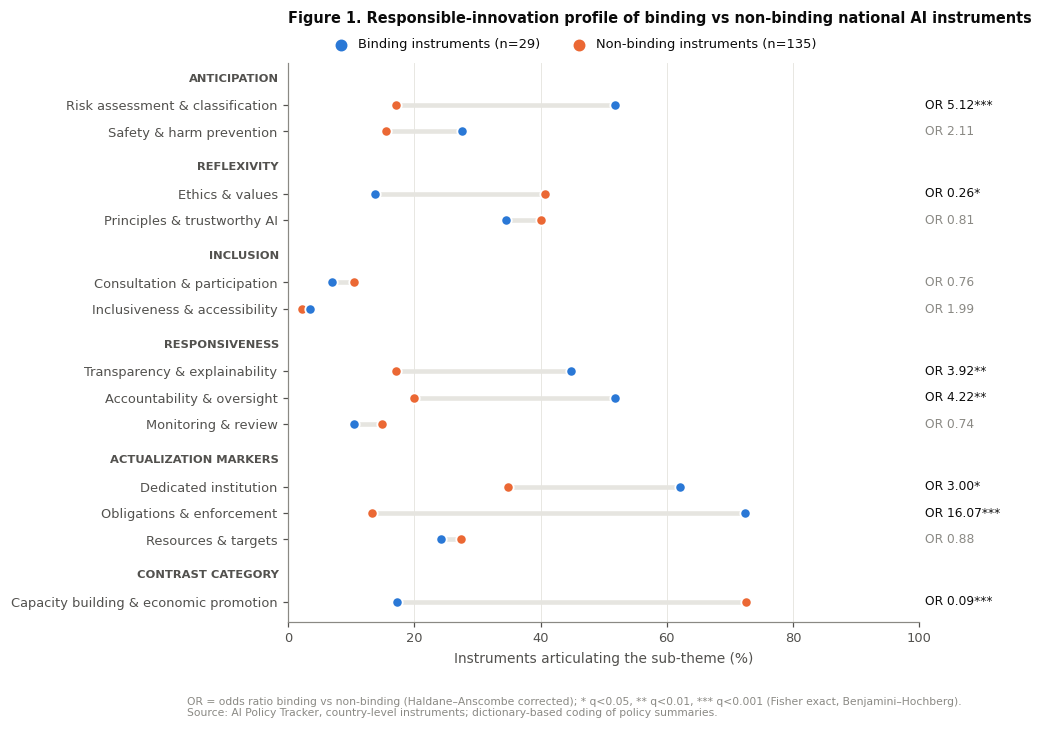

saved -> /kaggle/working/outputs/figures/Figure1_RQ1_RI_profile_dumbbell.pdf


In [10]:
order = ["Anticipation", "Reflexivity", "Inclusion", "Responsiveness", "Actualization", "Contrast"]
group_title = {"Actualization": "Actualization markers", "Contrast": "Contrast category"}
rows, y, ypos, headers = [], 0, {}, []
for g in order:
    headers.append((g, y)); y -= 1
    for c in CB[CB.dimension == g].code:
        ypos[c] = y; y -= 1
    y -= 0.35

fig, ax = plt.subplots(figsize=(7.4, 6.6))
d = t1.set_index("code")
for c, yy in ypos.items():
    pb, pn = d.loc[c, "pct_Binding"], d.loc[c, "pct_Non-binding"]
    ax.plot([pn, pb], [yy, yy], color=COL["grid"], lw=3, solid_capstyle="round", zorder=1)
    ax.scatter(pn, yy, s=46, color=COL["nonbinding"], edgecolor="white", linewidth=1.2, zorder=3)
    ax.scatter(pb, yy, s=46, color=COL["binding"], edgecolor="white", linewidth=1.2, zorder=3)
    q = d.loc[c, "q_bh"]
    ax.text(1.01, yy, f"OR {d.loc[c,'odds_ratio']:.2f}{stars(q)}", transform=mtrans.blended_transform_factory(ax.transAxes, ax.transData),
            va="center", ha="left", fontsize=8, color=COL["ink"] if q < 0.05 else COL["muted"])
ax.set_yticks(list(ypos.values()))
ax.set_yticklabels([LABEL[c] for c in ypos])
for g, yy in headers:
    ax.text(-0.015, yy, group_title.get(g, g).upper(), transform=mtrans.blended_transform_factory(ax.transAxes, ax.transData),
            ha="right", va="center", fontsize=7.5, fontweight="bold", color=COL["ink2"])
ax.set_xlim(0, 100); ax.set_ylim(y + 0.6, 0.6)
ax.set_xlabel("Instruments articulating the sub-theme (%)")
ax.grid(axis="y", visible=False)
nb, nn = int(inst.is_binding.sum()), int((~inst.is_binding).sum())
ax.scatter([], [], color=COL["binding"], s=46, label=f"Binding instruments (n={nb})")
ax.scatter([], [], color=COL["nonbinding"], s=46, label=f"Non-binding instruments (n={nn})")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=2, handletextpad=0.3)
ax.set_title("Figure 1. Responsible-innovation profile of binding vs non-binding national AI instruments",
             loc="left", pad=26, fontsize=9.5)
fig.text(0.0, -0.02, "OR = odds ratio binding vs non-binding (Haldane–Anscombe corrected); * q<0.05, ** q<0.01, *** q<0.001 "
         "(Fisher exact, Benjamini–Hochberg).\nSource: AI Policy Tracker, country-level instruments; dictionary-based coding of policy summaries.",
         fontsize=7, color=COL["muted"], ha="left")
save_fig(fig, "Figure1_RQ1_RI_profile_dumbbell")

## Step 9 · RQ2 – Government effectiveness, income and strategy adoption
**What this cell does:**
- **Table 2a**: adoption rates and Government Effectiveness of adopters vs non-adopters, overall and **within each income group** (Mann–Whitney U, Cliff's δ as effect size).
- **Table 2b**: logistic regressions of strategy adoption on GE: (M1) GE only; (M2) GE + income group; (M3) GE × income group. A likelihood-ratio test of M3 vs M2 tests whether the GE association is *conditional on income*.

GE is on the WGI standard-normal scale, so odds ratios are per 1 SD of GE.
**Research question:** RQ2. **Outputs:** *Table 2a, Table 2b*.

In [11]:
def cliffs_delta(x, y):
    u = stats.mannwhitneyu(x, y).statistic
    return 2 * u / (len(x) * len(y)) - 1

def group_compare(df, flag, value="ge"):
    a, b = df[df[flag]][value].dropna(), df[~df[flag]][value].dropna()
    if len(a) < 3 or len(b) < 3:
        return [len(a), len(b), a.mean(), b.mean(), np.nan, np.nan]
    return [len(a), len(b), a.mean(), b.mean(), cliffs_delta(a, b), stats.mannwhitneyu(a, b).pvalue]

d2 = cty.dropna(subset=['ge']).copy()
rows = [["All countries", *group_compare(d2, "has_strategy")]]
for g in INC_ORDER:
    rows.append([g, *group_compare(d2[d2.income3 == g], "has_strategy")])
t2a = pd.DataFrame(rows, columns=["Group", "n_adopters", "n_non_adopters", "GE_mean_adopters",
                                  "GE_mean_non_adopters", "cliffs_delta", "p_mannwhitney"])
t2a.insert(3, "adoption_rate_pct", (100 * t2a.n_adopters / (t2a.n_adopters + t2a.n_non_adopters)).round(1))
t2a["GE_diff"] = t2a.GE_mean_adopters - t2a.GE_mean_non_adopters
t2a_show = t2a.round(3).assign(p_mannwhitney=t2a.p_mannwhitney.map(fmt_p))
save_table(t2a_show, "Table2a_RQ2_GE_by_strategy_within_income")

# ---- logistic regressions ----------------------------------------------------
dm = d2.dropna(subset=["income3"]).copy()
dm["y"] = dm.has_strategy.astype(int)
dm["income3"] = dm.income3.astype(str)
REF = "C(income3, Treatment('Low & lower-middle'))"
models = {
    "M1: GE": f"y ~ ge",
    "M2: GE + income": f"y ~ ge + {REF}",
    "M3: GE × income": f"y ~ ge * {REF}",
}
fits = {k: smf.glm(f, data=dm, family=sm.families.Binomial()).fit() for k, f in models.items()}

def tidy(res, model):
    ci = res.conf_int()
    out = pd.DataFrame({"model": model, "term": res.params.index, "odds_ratio": np.exp(res.params),
                        "ci_lo": np.exp(ci[0]), "ci_hi": np.exp(ci[1]), "p": res.pvalues})
    out["term"] = (out.term.str.replace(REF, "income", regex=False)
                          .str.replace("[T.", " = ", regex=False).str.replace("]", "", regex=False))
    return out

t2b = pd.concat([tidy(r, k) for k, r in fits.items()], ignore_index=True)
fit_rows = []
for k, r in fits.items():
    fit_rows.append({"model": k, "term": "N / AIC / McFadden R²",
                     "odds_ratio": np.nan, "ci_lo": np.nan, "ci_hi": np.nan, "p": np.nan,
                     "fit": f"N={int(r.nobs)}; AIC={r.aic:.1f}; R²={1 - r.llf / r.llnull:.3f}"})
lr = 2 * (fits["M3: GE × income"].llf - fits["M2: GE + income"].llf)
lr_df = fits["M3: GE × income"].df_model - fits["M2: GE + income"].df_model
lr_p = stats.chi2.sf(lr, lr_df)
fit_rows.append({"model": "LR test M3 vs M2", "term": f"GE × income interaction (χ²={lr:.2f}, df={int(lr_df)})",
                 "p": lr_p, "fit": ""})
t2b = pd.concat([t2b, pd.DataFrame(fit_rows)], ignore_index=True)
t2b_show = t2b.copy()
for c in ["odds_ratio", "ci_lo", "ci_hi"]: t2b_show[c] = t2b_show[c].round(3)
t2b_show["p"] = t2b_show.p.map(fmt_p)
save_table(t2b_show.fillna(""), "Table2b_RQ2_logit_strategy_adoption")

# GE slope within each income group (from M3) for reporting
slopes = []
for g in INC_ORDER:
    s = dm[dm.income3 == g]
    if s.y.nunique() == 2:
        r = smf.glm("y ~ ge", data=s, family=sm.families.Binomial()).fit()
        slopes.append([g, len(s), int(s.y.sum()), np.exp(r.params['ge']), *np.exp(r.conf_int().loc['ge']), r.pvalues['ge']])
t2c = pd.DataFrame(slopes, columns=["income_group", "N", "adopters", "OR_per_SD_GE", "ci_lo", "ci_hi", "p"])
save_table(t2c.round(3).assign(p=t2c.p.map(fmt_p)), "Table2c_RQ2_GE_effect_by_income_group")

,Group,n_adopters,n_non_adopters,adoption_rate_pct,GE_mean_adopters,GE_mean_non_adopters,cliffs_delta,p_mannwhitney,GE_diff
0,All countries,76,119,39.0,0.623,-0.347,0.581,<0.001,0.970
1,Low & lower-middle,15,57,20.8,-0.162,-0.970,0.740,<0.001,0.808
2,Upper-middle,20,39,33.9,0.127,-0.178,0.282,0.080,0.305
3,High,41,23,64.1,1.153,0.912,0.258,0.090,0.241


saved -> /kaggle/working/outputs/tables/Table2a_RQ2_GE_by_strategy_within_income.csv


,model,term,odds_ratio,ci_lo,ci_hi,p,fit
0,M1: GE,Intercept,0.538,0.382,0.756,<0.001,
1,M1: GE,ge,3.669,2.409,5.586,<0.001,
2,M2: GE + income,Intercept,0.722,0.356,1.465,0.367,
3,M2: GE + income,income = High,0.522,0.143,1.908,0.326,
4,M2: GE + income,income = Upper-middle,0.727,0.291,1.815,0.495,
5,M2: GE + income,ge,4.737,2.4,9.35,<0.001,
6,M3: GE × income,Intercept,1.76,0.597,5.19,0.305,
7,M3: GE × income,income = High,0.495,0.111,2.208,0.357,
8,M3: GE × income,income = Upper-middle,0.298,0.088,1.011,0.052,
9,M3: GE × income,ge,31.413,4.904,201.236,<0.001,


saved -> /kaggle/working/outputs/tables/Table2b_RQ2_logit_strategy_adoption.csv


,income_group,N,adopters,OR_per_SD_GE,ci_lo,ci_hi,p
0,Low & lower-middle,72,15,31.413,4.904,201.236,<0.001
1,Upper-middle,59,20,5.006,1.167,21.470,0.030
2,High,64,41,1.999,0.821,4.866,0.127


saved -> /kaggle/working/outputs/tables/Table2c_RQ2_GE_effect_by_income_group.csv


### Figure 2 · RQ2 adoption probability and GE distributions by income group
**What this cell does:** panel (a) plots the predicted probability of having a national AI strategy across the observed range of GE for each income group (model M3, 95 % CI bands); panel (b) shows every country's GE score split by adoption status within each income group (dots = countries, bars = medians), annotated with Mann–Whitney p-values. Together they show *where* governance capacity matters for adoption.
**Research question:** RQ2. **Output:** *Figure 2*.

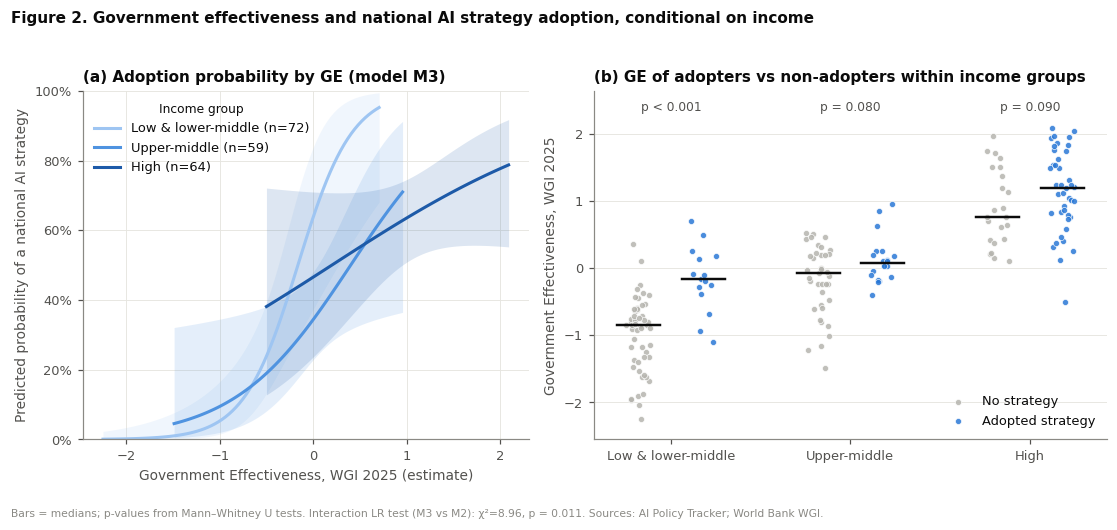

saved -> /kaggle/working/outputs/figures/Figure2_RQ2_GE_income_strategy_adoption.pdf


In [12]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(10.2, 4.3), gridspec_kw={"width_ratios": [1, 1.15]})
m3 = fits["M3: GE × income"]
for g, col in zip(INC_ORDER, INCOME_SEQ):
    s = dm[dm.income3 == g]
    grid = pd.DataFrame({"ge": np.linspace(s['ge'].min(), s['ge'].max(), 80), "income3": g})
    pr = m3.get_prediction(grid).summary_frame()
    axa.fill_between(grid['ge'], pr.mean_ci_lower, pr.mean_ci_upper, color=col, alpha=0.15, lw=0)
    axa.plot(grid['ge'], pr["mean"], color=col, lw=2, label=f"{g} (n={len(s)})")
axa.set_ylim(0, 1); axa.set_xlabel(f"Government Effectiveness, WGI {WGI_YEAR} (estimate)")
axa.set_ylabel("Predicted probability of a national AI strategy")
axa.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
axa.legend(loc="upper left", title="Income group", title_fontsize=8)
axa.set_title("(a) Adoption probability by GE (model M3)", loc="left")

for i, g in enumerate(INC_ORDER):
    s = d2[d2.income3 == g]
    for j, (flag, col, lab) in enumerate([(False, COL["none"], "No strategy"), (True, COL["binding"], "Adopted strategy")]):
        v = s[s.has_strategy == flag]['ge']
        x = i + (-0.18 if j == 0 else 0.18) + rng.uniform(-0.07, 0.07, len(v))
        axb.scatter(x, v, s=16, color=col, alpha=0.85, edgecolor="white", linewidth=0.5, zorder=3,
                    label=lab if i == 0 else None)
        axb.plot([i + (-0.18 if j == 0 else 0.18) - 0.12, i + (-0.18 if j == 0 else 0.18) + 0.12],
                 [v.median()] * 2, color=COL["ink"], lw=1.6, zorder=4)
    p = t2a.set_index("Group").loc[g, "p_mannwhitney"]
    axb.text(i, d2['ge'].max() + 0.25, f"{pstr(p)}", ha="center", fontsize=8, color=COL["ink2"])
axb.set_xticks(range(3)); axb.set_xticklabels(INC_ORDER)
axb.set_ylabel(f"Government Effectiveness, WGI {WGI_YEAR}")
axb.set_ylim(d2['ge'].min() - 0.3, d2['ge'].max() + 0.55); axb.grid(axis="x", visible=False)
axb.legend(loc="lower right")
axb.set_title("(b) GE of adopters vs non-adopters within income groups", loc="left")
fig.suptitle("Figure 2. Government effectiveness and national AI strategy adoption, conditional on income",
             x=0.01, ha="left", fontsize=10, fontweight="bold", y=1.03)
fig.text(0.01, -0.04, f"Bars = medians; p-values from Mann–Whitney U tests. Interaction LR test (M3 vs M2): χ²={lr:.2f}, {pstr(lr_p)}. "
         "Sources: AI Policy Tracker; World Bank WGI.", fontsize=7, color=COL["muted"])
fig.tight_layout()
save_fig(fig, "Figure2_RQ2_GE_income_strategy_adoption")

## Step 10 · RQ3 – From articulation to actualization: decoupling test
**What this cell does:**
- **Table 3a** compares GE across the three policy stages (*No recorded instrument → Non-binding only → Binding enacted*) with a Kruskal–Wallis test and the two adjacent pairwise Mann–Whitney tests.
- **Table 3b** estimates a two-stage model with **Firth penalised logistic regression** (appropriate because few countries have binding instruments): Stage 1 – *having any AI policy* on GE; Stage 2 – among countries with a policy, *having an enacted binding instrument* on GE, controlling for EU membership. P-values come from penalised likelihood-ratio tests.
- **Table 3c** (RQ3b) – among countries with an adopted strategy, is GE associated with the *implementation concreteness* of their strategy text (0–3 actualization markers)? Spearman correlation.

Decoupling is supported if GE predicts Stage 1 (articulation) but not Stage 2 (actualization).
**Research question:** RQ3. **Outputs:** *Table 3a–3c*.

In [13]:
def firth_logit(y, X, names, max_iter=200, tol=1e-9):
    # Firth (1993) penalised-likelihood logistic regression with penalised LR tests per term.
    # The penalised LR test follows Heinze & Schemper (2002) / R logistf: the restricted model fixes
    # beta_k = 0 but keeps the Jeffreys penalty of the FULL design matrix, so the two fits are comparable.
    y = np.asarray(y, float); X = np.asarray(X, float)
    def pll(b):
        p = np.clip(1 / (1 + np.exp(-X @ b)), 1e-12, 1 - 1e-12); W = p * (1 - p)
        sign, logdet = np.linalg.slogdet(X.T @ (X * W[:, None]))
        return np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)) + 0.5 * logdet
    def fit(free):
        b = np.zeros(X.shape[1])
        for _ in range(max_iter):
            p = 1 / (1 + np.exp(-X @ b)); W = p * (1 - p)
            XtWX = X.T @ (X * W[:, None]); inv = np.linalg.inv(XtWX)
            A = X * np.sqrt(W)[:, None]
            h = np.einsum("ij,jk,ik->i", A, inv, A)
            U = X.T @ (y - p + h * (0.5 - p))
            step = np.zeros_like(b)
            step[free] = np.linalg.solve(XtWX[np.ix_(free, free)], U[free])
            ll_old, t = pll(b), 1.0          # step-halving guard
            while pll(b + t * step) < ll_old - 1e-12 and t > 1e-4:
                t /= 2
            b = b + t * step
            if np.max(np.abs(t * step)) < tol: break
        p = 1 / (1 + np.exp(-X @ b)); W = p * (1 - p)
        inv = np.linalg.inv(X.T @ (X * W[:, None]))
        return b, np.sqrt(np.diag(inv)), pll(b)
    allk = np.arange(X.shape[1])
    b, se, ll_full = fit(allk)
    rows = []
    for k, nm in enumerate(names):
        if k == 0:
            p_lr = np.nan
        else:
            _, _, ll_red = fit(allk[allk != k])
            p_lr = stats.chi2.sf(max(0.0, 2 * (ll_full - ll_red)), 1)
        rows.append([nm, np.exp(b[k]), np.exp(b[k] - 1.96 * se[k]), np.exp(b[k] + 1.96 * se[k]), p_lr])
    return pd.DataFrame(rows, columns=["term", "odds_ratio", "ci_lo", "ci_hi", "p_penalised_LR"])

def run_firth(df, outcome, predictors, label):
    s = df.dropna(subset=[outcome] + predictors)
    X = np.column_stack([np.ones(len(s))] + [s[p].astype(float) for p in predictors])
    res = firth_logit(s[outcome].astype(int), X, ["Intercept"] + predictors)
    res.insert(0, "model", label); res["N"] = len(s); res["events"] = int(s[outcome].sum())
    return res

d3 = cty.dropna(subset=['ge']).copy()
d3["eu"] = d3.eu_member.astype(int)

# ---- Table 3a: GE by policy stage ----------------------------------------------
stages = list(d3.policy_stage.cat.categories)
g = [d3[d3.policy_stage == s]['ge'] for s in stages]
kw = stats.kruskal(*g)
t3a = pd.DataFrame({"policy_stage": stages, "n": [len(x) for x in g], "GE_mean": [x.mean() for x in g],
                    "GE_median": [x.median() for x in g]})
pair = [("No recorded instrument", "Non-binding only"), ("Non-binding only", "Binding enacted"),
        ("No recorded instrument", "Binding enacted")]
pair_rows = []
for a, b in pair:
    xa, xb = d3[d3.policy_stage == b]['ge'], d3[d3.policy_stage == a]['ge']
    pair_rows.append([f"{b} vs {a}", len(xa), len(xb), xa.mean() - xb.mean(), cliffs_delta(xa, xb),
                      stats.mannwhitneyu(xa, xb).pvalue])
t3a_pairs = pd.DataFrame(pair_rows, columns=["comparison", "n_1", "n_2", "GE_diff", "cliffs_delta", "p_mannwhitney"])
from statsmodels.stats.multitest import multipletests
t3a_pairs["p_holm"] = multipletests(t3a_pairs.p_mannwhitney, method="holm")[1]
print(f"Kruskal–Wallis across stages: H={kw.statistic:.2f}, {pstr(kw.pvalue)}")
save_table(t3a.round(3), "Table3a_RQ3_GE_by_policy_stage")
save_table(t3a_pairs.round(3).assign(p_mannwhitney=t3a_pairs.p_mannwhitney.map(fmt_p),
                                     p_holm=t3a_pairs.p_holm.map(fmt_p)), "Table3a2_RQ3_pairwise_stage_tests")

# ---- Table 3b: two-stage Firth models ---------------------------------------------
adopters = d3[d3.has_any_policy]
t3b = pd.concat([
    run_firth(d3, "has_any_policy", ['ge'], "Stage 1: any AI policy ~ GE (all countries)"),
    run_firth(d3, "has_strategy", ['ge'], "Stage 1b: adopted strategy ~ GE (all countries)"),
    run_firth(adopters, "binding_national", ['ge'], "Stage 2: enacted binding ~ GE (countries with policy)"),
    run_firth(adopters, "binding_national", ["ge", "eu"], "Stage 2: enacted binding ~ GE + EU member"),
], ignore_index=True)
t3b_show = t3b.copy()
for c in ["odds_ratio", "ci_lo", "ci_hi"]: t3b_show[c] = t3b_show[c].round(3)
t3b_show["p_penalised_LR"] = t3b_show.p_penalised_LR.map(fmt_p)
save_table(t3b_show, "Table3b_RQ3_two_stage_firth_logit")

# ---- Table 3c: implementation concreteness of strategies vs GE -------------------
strat = inst[inst.adopted_strategy].groupby("country").agg(
    impl_concreteness=("impl_concreteness", "max"), n_ri_dims=("n_ri_dims", "max"))
d3c = d3.merge(strat, left_on="country", right_index=True)
rows = []
for v, lab in [("impl_concreteness", "Implementation concreteness (0–3)"), ("n_ri_dims", "Number of RI dimensions (0–4)")]:
    r = stats.spearmanr(d3c['ge'], d3c[v])
    rows.append([lab, len(d3c), d3c[v].mean(), r.statistic, r.pvalue])
t3c = pd.DataFrame(rows, columns=["strategy_content_measure", "N_countries", "mean", "spearman_rho_with_GE", "p"])
save_table(t3c.round(3).assign(p=t3c.p.map(fmt_p)), "Table3c_RQ3_strategy_concreteness_vs_GE")

Kruskal–Wallis across stages: H=52.04, p < 0.001


,policy_stage,n,GE_mean,GE_median
0,No recorded instrument,90,-0.517,-0.628
1,Non-binding only,88,0.502,0.312
2,Binding enacted,17,0.502,0.322


saved -> /kaggle/working/outputs/tables/Table3a_RQ3_GE_by_policy_stage.csv


,comparison,n_1,n_2,GE_diff,cliffs_delta,p_mannwhitney,p_holm
0,Non-binding only vs No recorded instrument,88,90,1.019,0.593,<0.001,<0.001
1,Binding enacted vs Non-binding only,17,88,-0.000,0.024,0.879,0.879
2,Binding enacted vs No recorded instrument,17,90,1.019,0.635,<0.001,<0.001


saved -> /kaggle/working/outputs/tables/Table3a2_RQ3_pairwise_stage_tests.csv


,model,term,odds_ratio,ci_lo,ci_hi,p_penalised_LR,N,events
0,Stage 1: any AI policy ~ GE (all countries),Intercept,1.204,0.864,1.678,n/a,195,105
1,Stage 1: any AI policy ~ GE (all countries),ge,4.225,2.695,6.625,<0.001,195,105
2,Stage 1b: adopted strategy ~ GE (all countries),Intercept,0.542,0.386,0.761,n/a,195,76
3,Stage 1b: adopted strategy ~ GE (all countries),ge,3.572,2.357,5.412,<0.001,195,76
4,Stage 2: enacted binding ~ GE (countries with policy),Intercept,0.202,0.110,0.368,n/a,105,17
5,Stage 2: enacted binding ~ GE (countries with policy),ge,1.007,0.535,1.896,0.983,105,17
6,Stage 2: enacted binding ~ GE + EU member,Intercept,0.219,0.118,0.405,n/a,105,17
7,Stage 2: enacted binding ~ GE + EU member,ge,1.174,0.592,2.327,0.644,105,17
8,Stage 2: enacted binding ~ GE + EU member,eu,0.549,0.137,2.207,0.380,105,17


saved -> /kaggle/working/outputs/tables/Table3b_RQ3_two_stage_firth_logit.csv


,strategy_content_measure,N_countries,mean,spearman_rho_with_GE,p
0,Implementation concreteness (0–3),76,0.803,0.317,0.005
1,Number of RI dimensions (0–4),76,0.855,0.158,0.172


saved -> /kaggle/working/outputs/tables/Table3c_RQ3_strategy_concreteness_vs_GE.csv


### Figure 3 · RQ3 articulation vs actualization
**What this cell does:** panel (a) shows GE for each country across the three policy stages with medians and the pairwise test results – a rise from *no instrument* to *non-binding only* but no further rise to *binding enacted* indicates decoupling; panel (b) plots, for countries with an adopted strategy, GE against the strategy's implementation concreteness score (jittered), with the Spearman correlation.
**Research question:** RQ3. **Output:** *Figure 3*.

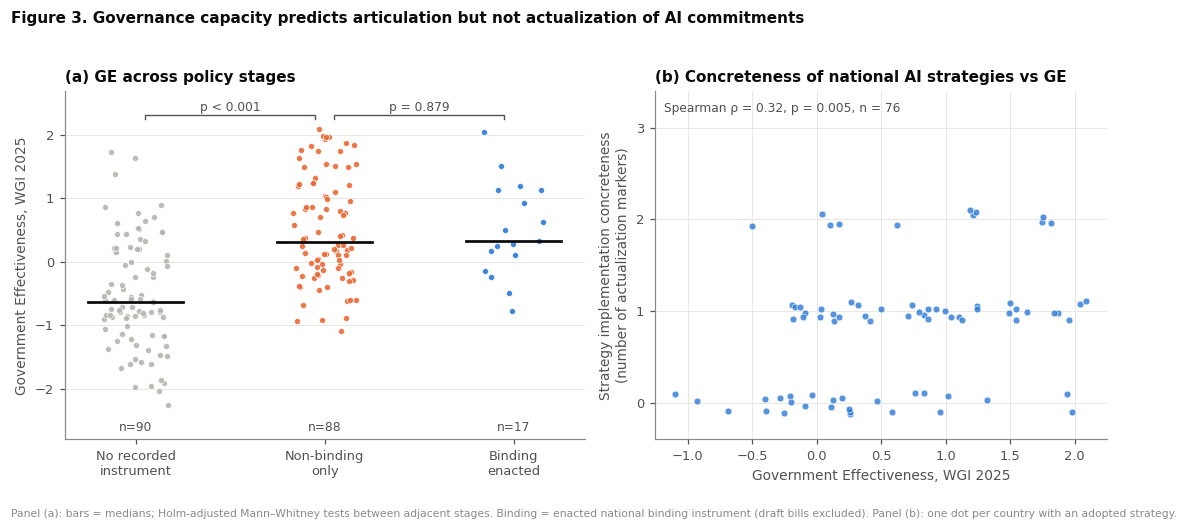

saved -> /kaggle/working/outputs/figures/Figure3_RQ3_articulation_vs_actualization.pdf


In [14]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(10.2, 4.3), gridspec_kw={"width_ratios": [1.15, 1]})
stage_col = {"No recorded instrument": COL["none"], "Non-binding only": COL["nonbinding"], "Binding enacted": COL["binding"]}
for i, s in enumerate(stages):
    v = d3[d3.policy_stage == s]['ge']
    axa.scatter(i + rng.uniform(-0.17, 0.17, len(v)), v, s=16, color=stage_col[s], edgecolor="white",
                linewidth=0.5, alpha=0.9, zorder=3)
    axa.plot([i - 0.25, i + 0.25], [v.median()] * 2, color=COL["ink"], lw=1.8, zorder=4)
    axa.text(i, d3['ge'].min() - 0.42, f"n={len(v)}", ha="center", fontsize=8, color=COL["ink2"])
top = d3['ge'].max()
for k, (a, b) in enumerate(pair[:2]):
    i0, i1 = stages.index(a), stages.index(b)
    yb = top + 0.22 + 0.0 * k
    axa.plot([i0 + 0.05, i0 + 0.05, i1 - 0.05, i1 - 0.05], [yb - 0.07, yb, yb, yb - 0.07], color=COL["ink2"], lw=0.9)
    p = t3a_pairs.loc[k, "p_holm"]
    axa.text((i0 + i1) / 2, yb + 0.06, f"{pstr(p)}", ha="center", fontsize=8, color=COL["ink2"])
axa.set_xticks(range(3)); axa.set_xticklabels(["No recorded\ninstrument", "Non-binding\nonly", "Binding\nenacted"])
axa.set_ylim(d3['ge'].min() - 0.55, top + 0.6); axa.grid(axis="x", visible=False)
axa.set_ylabel(f"Government Effectiveness, WGI {WGI_YEAR}")
axa.set_title("(a) GE across policy stages", loc="left")

xj = d3c.impl_concreteness + rng.uniform(-0.12, 0.12, len(d3c))
axb.scatter(d3c['ge'], xj, s=20, color=COL["binding"], alpha=0.8, edgecolor="white", linewidth=0.5, zorder=3)
r = t3c.iloc[0]
axb.set_yticks([0, 1, 2, 3]); axb.set_ylim(-0.4, 3.4)
axb.set_xlabel(f"Government Effectiveness, WGI {WGI_YEAR}")
axb.set_ylabel("Strategy implementation concreteness\n(number of actualization markers)")
axb.text(0.02, 0.97, f"Spearman ρ = {r.spearman_rho_with_GE:.2f}, {pstr(r.p)}, n = {int(r.N_countries)}",
         transform=axb.transAxes, va="top", fontsize=8, color=COL["ink2"])
axb.set_title("(b) Concreteness of national AI strategies vs GE", loc="left")
fig.suptitle("Figure 3. Governance capacity predicts articulation but not actualization of AI commitments",
             x=0.01, ha="left", fontsize=10, fontweight="bold", y=1.03)
fig.text(0.01, -0.04, "Panel (a): bars = medians; Holm-adjusted Mann–Whitney tests between adjacent stages. "
         "Binding = enacted national binding instrument (draft bills excluded). Panel (b): one dot per country with an adopted strategy.",
         fontsize=7, color=COL["muted"])
fig.tight_layout()
save_fig(fig, "Figure3_RQ3_articulation_vs_actualization")

## Step 11 · RQ4 – Pre-generative-AI vs generative-AI period
**What this cell does:** assigns dated country-level instruments to the **pre-generative-AI period (2017–2022)** or the **generative-AI period (2023 onward)** and compares the two periods on legal status (binding share), instrument types and the RI/actualization profile, using Fisher exact tests with BH correction (*Table 4*). Undated instruments are reported and excluded.
**Research question:** RQ4. **Output:** *Table 4*.

In [15]:
d4 = inst.dropna(subset=["year"]).copy()
d4 = d4[d4.year >= 2017]
d4["period"] = np.where(d4.year >= 2023, "2023+", "2017–2022")
print(f"Dated instruments: {len(d4)} of {len(inst)} (undated excluded: {inst.year.isna().sum()}; pre-2017: {(inst.year < 2017).sum()})")

TYPE_GROUP = {"strategy": "type_strategy", "act": "type_hard_law", "regulation": "type_hard_law",
              "bill": "type_hard_law", "executive_order": "type_hard_law"}
d4["type_strategy"] = (d4.instrument_type == "strategy").astype(int)
d4["type_hard_law"] = d4.instrument_type.isin(["act", "regulation", "bill", "executive_order"]).astype(int)
d4["type_soft_other"] = 1 - d4.type_strategy - d4.type_hard_law
d4["binding"] = d4.is_binding.astype(int)
lab4 = {**LABEL, "binding": "Binding instrument", "type_strategy": "Type: strategy",
        "type_hard_law": "Type: act / regulation / bill / executive order",
        "type_soft_other": "Type: guidance / framework / policy / other"}
rq4_codes = ["binding", "type_strategy", "type_hard_law", "type_soft_other"] + dim_codes + ["cap_capacity"]
t4 = compare_binary(d4, "period", rq4_codes, "2023+", "2017–2022", labels=lab4)
t4_show = t4.copy()
for c in ["pct_2023+", "pct_2017–2022", "diff_pp"]: t4_show[c] = t4_show[c].round(1)
for c in ["odds_ratio", "or_ci_lo", "or_ci_hi"]: t4_show[c] = t4_show[c].round(2)
t4_show["p_fisher"] = t4_show.p_fisher.map(fmt_p); t4_show["q_bh"] = t4_show.q_bh.map(fmt_p)
save_table(t4_show, "Table4_RQ4_period_comparison")

annual = pd.crosstab(d4.year.astype(int), d4.binding_label)
save_table(annual.reset_index(), "Table4b_RQ4_annual_counts_by_legal_status")

Dated instruments: 131 of 164 (undated excluded: 33; pre-2017: 0)


,code,label,n_2023+,N_2023+,pct_2023+,n_2017–2022,N_2017–2022,pct_2017–2022,diff_pp,odds_ratio,or_ci_lo,or_ci_hi,p_fisher,q_bh
0,binding,Binding instrument,20,88,22.7,4,43,9.3,13.4,2.63,0.88,7.84,0.091,0.114
1,type_strategy,Type: strategy,35,88,39.8,32,43,74.4,-34.6,0.23,0.11,0.52,<0.001,0.002
2,type_hard_law,Type: act / regulation / bill / executive order,23,88,26.1,5,43,11.6,14.5,2.51,0.91,6.90,0.070,0.101
3,type_soft_other,Type: guidance / framework / policy / other,30,88,34.1,6,43,14.0,20.1,3.01,1.17,7.71,0.021,0.042
4,dim_anticipation,Anticipation,38,88,43.2,7,43,16.3,26.9,3.71,1.52,9.04,0.003,0.010
5,dim_reflexivity,Reflexivity,46,88,52.3,29,43,67.4,-15.2,0.54,0.25,1.14,0.132,0.147
6,dim_inclusion,Inclusion,14,88,15.9,5,43,11.6,4.3,1.36,0.47,3.92,0.605,0.605
7,dim_responsiveness,Responsiveness,47,88,53.4,11,43,25.6,27.8,3.23,1.47,7.13,0.003,0.010
8,dim_actualization,Actualization,70,88,79.5,24,43,55.8,23.7,3.03,1.38,6.65,0.007,0.017
9,cap_capacity,Capacity building & economic promotion,47,88,53.4,31,43,72.1,-18.7,0.45,0.21,0.99,0.057,0.096


saved -> /kaggle/working/outputs/tables/Table4_RQ4_period_comparison.csv


binding_label,year,Binding,Non-binding
0,2017,0,4
1,2018,1,4
2,2019,0,7
3,2020,1,12
4,2021,1,7
5,2022,1,5
6,2023,7,12
7,2024,2,26
8,2025,11,22
9,2026,0,8


saved -> /kaggle/working/outputs/tables/Table4b_RQ4_annual_counts_by_legal_status.csv


### Figure 4 · RQ4 temporal shift
**What this cell does:** panel (a) shows the annual number of country-level AI instruments by legal status, with the start of the generative-AI period marked (the final year is partial); panel (b) is a dumbbell chart of the share of instruments with each characteristic in 2017–2022 (gray) vs 2023+ (green), with BH-adjusted significance.
**Research question:** RQ4. **Output:** *Figure 4*.

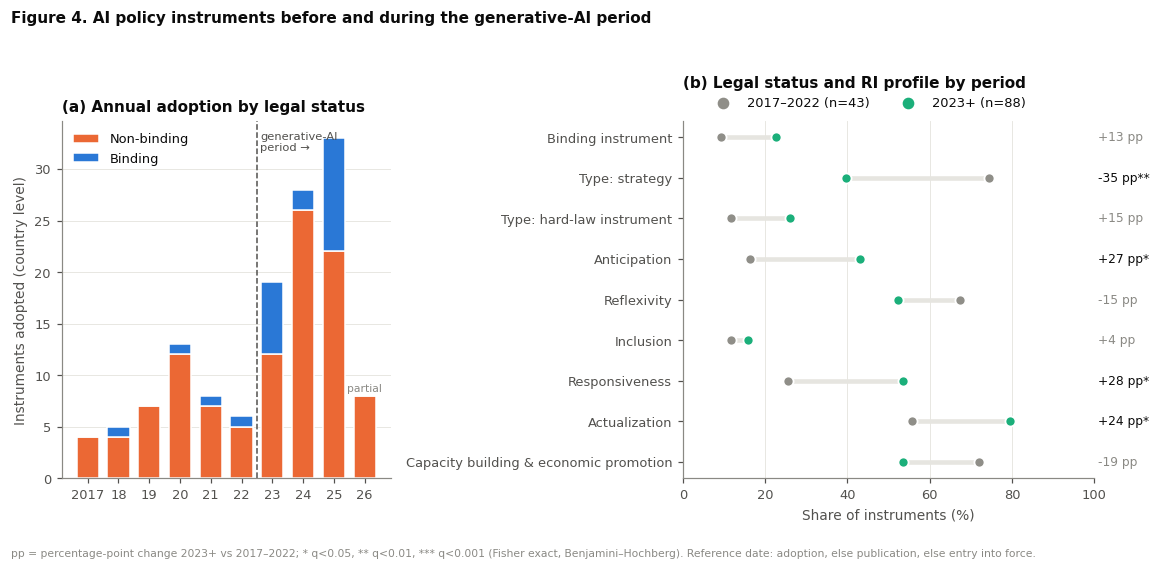

saved -> /kaggle/working/outputs/figures/Figure4_RQ4_period_shift.pdf


In [16]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(10.6, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
yrs = annual.index.values
nbv = annual.get("Non-binding", pd.Series(0, index=yrs)).values
bv = annual.get("Binding", pd.Series(0, index=yrs)).values
axa.bar(yrs, nbv, width=0.72, color=COL["nonbinding"], label="Non-binding", edgecolor="white", linewidth=1)
axa.bar(yrs, bv, width=0.72, bottom=nbv, color=COL["binding"], label="Binding", edgecolor="white", linewidth=1)
axa.axvline(2022.5, color=COL["ink2"], lw=1, ls="--")
axa.text(2022.6, max(nbv + bv) * 1.02, "generative-AI\nperiod →", fontsize=7.5, color=COL["ink2"], va="top")
last = int(yrs.max())
axa.text(last, (nbv + bv)[-1] + 0.4, "partial", ha="center", fontsize=7, color=COL["muted"])
axa.set_xticks(yrs); axa.set_xticklabels([str(y)[2:] if y != yrs[0] else str(y) for y in yrs])
axa.set_ylabel("Instruments adopted (country level)"); axa.grid(axis="x", visible=False)
axa.legend(loc="upper left")
axa.set_title("(a) Annual adoption by legal status", loc="left")

show = ["binding", "type_strategy", "type_hard_law"] + dim_codes + ["cap_capacity"]
d = t4.set_index("code")
for k, c in enumerate(show):
    yy = -k
    p0, p1 = d.loc[c, "pct_2017–2022"], d.loc[c, "pct_2023+"]
    axb.plot([p0, p1], [yy, yy], color=COL["grid"], lw=3, solid_capstyle="round", zorder=1)
    axb.scatter(p0, yy, s=44, color=COL["pre"], edgecolor="white", linewidth=1.2, zorder=3)
    axb.scatter(p1, yy, s=44, color=COL["post"], edgecolor="white", linewidth=1.2, zorder=3)
    q = d.loc[c, "q_bh"]
    axb.text(1.01, yy, f"{d.loc[c,'diff_pp']:+.0f} pp{stars(q)}",
             transform=mtrans.blended_transform_factory(axb.transAxes, axb.transData),
             va="center", fontsize=8, color=COL["ink"] if q < 0.05 else COL["muted"])
axb.set_yticks([-k for k in range(len(show))])
axb.set_yticklabels([lab4[c].replace("Type: act / regulation / bill / executive order", "Type: hard-law instrument") for c in show])
axb.set_xlim(0, 100); axb.grid(axis="y", visible=False)
axb.set_xlabel("Share of instruments (%)")
n0, n1 = (d4.period == "2017–2022").sum(), (d4.period == "2023+").sum()
axb.scatter([], [], color=COL["pre"], s=44, label=f"2017–2022 (n={n0})")
axb.scatter([], [], color=COL["post"], s=44, label=f"2023+ (n={n1})")
axb.legend(loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=2)
axb.set_title("(b) Legal status and RI profile by period", loc="left", pad=22)
fig.suptitle("Figure 4. AI policy instruments before and during the generative-AI period",
             x=0.01, ha="left", fontsize=10, fontweight="bold", y=1.04)
fig.text(0.01, -0.04, "pp = percentage-point change 2023+ vs 2017–2022; * q<0.05, ** q<0.01, *** q<0.001 (Fisher exact, Benjamini–Hochberg). "
         "Reference date: adoption, else publication, else entry into force.", fontsize=7, color=COL["muted"])
fig.tight_layout()
save_fig(fig, "Figure4_RQ4_period_shift")

## Step 12 · Robustness checks
**What this cell does:** re-estimates the key quantity of each RQ under alternative specifications that address the main threats to validity:
- RQ1 – restrict to records with `review_status = verified` **or** `confidence_level = high`;
- RQ2 – replace GE {latest year} with the **pre-period GE (mean 2017–2022)**, and with **Regulatory Quality**;
- RQ3 – Stage 2 with pre-period GE, **excluding EU members**, and with the **EU-adjusted binding outcome**;
- RQ4 – binding-share change on verified/high-confidence records only.

**Methodological step:** Step 12. Output: *Table S3 – robustness*.

In [17]:
rob = []
# RQ1
hq = inst[(inst.review_status == "verified") | (inst.confidence_level == "high")]
r1 = compare_binary(hq.assign(grp=hq.binding_label), "grp", ["ref_ethics", "ant_risk", "res_transparency",
                    "res_accountability", "act_obligation", "cap_capacity"], "Binding", "Non-binding")
for _, r in r1.iterrows():
    rob.append(["RQ1", f"{r.label}: binding vs non-binding", "verified or high-confidence records",
                r.odds_ratio, r.or_ci_lo, r.or_ci_hi, r.p_fisher, r.N_Binding + r["N_Non-binding"]])
# RQ2
for var, lab in [("ge", f"GE {WGI_YEAR} (main)"), ("ge_pre", "GE mean 2017–2022"), ("rq", f"Regulatory Quality {WGI_YEAR}")]:
    s = cty.dropna(subset=[var, "income3"]).copy(); s["y"] = s.has_strategy.astype(int); s["income3"] = s.income3.astype(str)
    res = smf.glm(f"y ~ {var} + {REF}", data=s, family=sm.families.Binomial()).fit()
    ci = np.exp(res.conf_int().loc[var])
    rob.append(["RQ2", "Strategy adoption ~ governance + income (OR per SD)", lab,
                np.exp(res.params[var]), ci[0], ci[1], res.pvalues[var], int(res.nobs)])
# RQ3
for lab, df, outcome, preds in [
    (f"GE {WGI_YEAR} (main)", cty[cty.has_any_policy].dropna(subset=['ge']), "binding_national", ['ge']),
    ("GE mean 2017–2022", cty[cty.has_any_policy].dropna(subset=["ge_pre"]), "binding_national", ["ge_pre"]),
    ("Excluding EU members", cty[cty.has_any_policy & ~cty.eu_member].dropna(subset=['ge']), "binding_national", ['ge']),
    ("EU AI Act attributed to members", cty[cty.has_any_policy].dropna(subset=['ge']), "binding_eu_adj", ['ge']),
    (f"Regulatory Quality {WGI_YEAR}", cty[cty.has_any_policy].dropna(subset=["rq"]), "binding_national", ["rq"]),
]:
    r = run_firth(df, outcome, preds, lab).iloc[1]
    rob.append(["RQ3", "Stage 2: binding among countries with policy (Firth OR)", lab,
                r.odds_ratio, r.ci_lo, r.ci_hi, r.p_penalised_LR, int(r.N)])
# RQ4
hq4 = d4[(d4.review_status == "verified") | (d4.confidence_level == "high")]
r4 = compare_binary(hq4, "period", ["binding", "dim_responsiveness", "cap_capacity"], "2023+", "2017–2022", labels=lab4)
for _, r in r4.iterrows():
    rob.append(["RQ4", f"{r.label}: 2023+ vs 2017–2022", "verified or high-confidence records",
                r.odds_ratio, r.or_ci_lo, r.or_ci_hi, r.p_fisher, r["N_2023+"] + r["N_2017–2022"]])

ts3 = pd.DataFrame(rob, columns=["RQ", "estimate", "specification", "odds_ratio", "ci_lo", "ci_hi", "p", "N"])
save_table(ts3.round(3).assign(p=ts3.p.map(fmt_p)), "TableS3_robustness_checks")

,RQ,estimate,specification,odds_ratio,ci_lo,ci_hi,p,N
0,RQ1,Ethics & values: binding vs non-binding,verified or high-confidence records,0.253,0.087,0.733,0.005,159
1,RQ1,Risk assessment & classification: binding vs non-binding,verified or high-confidence records,6.245,2.620,14.883,<0.001,159
2,RQ1,Transparency & explainability: binding vs non-binding,verified or high-confidence records,4.021,1.710,9.457,0.002,159
3,RQ1,Accountability & oversight: binding vs non-binding,verified or high-confidence records,4.571,1.964,10.640,<0.001,159
4,RQ1,Obligations & enforcement: binding vs non-binding,verified or high-confidence records,17.587,6.696,46.191,<0.001,159
5,RQ1,Capacity building & economic promotion: binding vs non-binding,verified or high-confidence records,0.080,0.029,0.218,<0.001,159
6,RQ2,Strategy adoption ~ governance + income (OR per SD),GE 2025 (main),4.737,2.400,9.350,<0.001,195
7,RQ2,Strategy adoption ~ governance + income (OR per SD),GE mean 2017–2022,3.640,1.941,6.824,<0.001,195
8,RQ2,Strategy adoption ~ governance + income (OR per SD),Regulatory Quality 2025,3.472,1.771,6.807,<0.001,195
9,RQ3,Stage 2: binding among countries with policy (Firth OR),GE 2025 (main),1.007,0.535,1.896,0.983,105


saved -> /kaggle/working/outputs/tables/TableS3_robustness_checks.csv


## Step 13 · Key findings (generated from the results above)
**What this cell does:** prints a short, data-driven summary of the main result for each research question, pulling every number from the tables computed above (nothing is typed by hand), ready to be adapted for the Results section.

In [18]:
t1i = t1.set_index("code"); t4i = t4.set_index("code")
def line(c, tab, g1, g0):
    r = tab.loc[c]
    return f"{r.label}: {r[f'pct_{g1}']:.0f}% vs {r[f'pct_{g0}']:.0f}% (OR {r.odds_ratio:.2f}, {pstr(r.q_bh, 'q')})"

st1 = t3b[t3b.model.str.startswith("Stage 1:") & (t3b.term == "ge")].iloc[0]
st2 = t3b[t3b.model.str.contains("GE \\+ EU") & (t3b.term == "ge")].iloc[0]
eu_r = ts3[(ts3.RQ == "RQ3") & ts3.specification.str.startswith("EU AI Act")].iloc[0]
txt = f'''
**RQ1 – RI profile (binding vs non-binding).**
- {line("ref_ethics", t1i, "Binding", "Non-binding")}
- {line("ant_risk", t1i, "Binding", "Non-binding")}
- {line("res_transparency", t1i, "Binding", "Non-binding")}
- {line("res_accountability", t1i, "Binding", "Non-binding")}
- {line("act_obligation", t1i, "Binding", "Non-binding")}
- {line("cap_capacity", t1i, "Binding", "Non-binding")}

**RQ2 – GE and strategy adoption.** Overall, adopters' mean GE is {t2a.loc[0,'GE_mean_adopters']:.2f} vs {t2a.loc[0,'GE_mean_non_adopters']:.2f}
(Cliff's δ = {t2a.loc[0,'cliffs_delta']:.2f}, {pstr(t2a.loc[0,'p_mannwhitney'])}). Within income groups:
''' + "\n".join(f"- {r.Group}: adoption {r.adoption_rate_pct:.0f}%, GE difference {r.GE_diff:+.2f}, δ = {r.cliffs_delta:.2f}, {pstr(r.p_mannwhitney)}"
               for r in t2a.iloc[1:].itertuples()) + f'''
- GE × income interaction (LR test): χ² = {lr:.2f}, {pstr(lr_p)}.

**RQ3 – Articulation vs actualization.** Stage 1 (any AI policy): OR per SD GE = {st1.odds_ratio:.2f}
[{st1.ci_lo:.2f}, {st1.ci_hi:.2f}], {pstr(st1.p_penalised_LR)}. Stage 2 (enacted binding among countries with policy, EU-controlled):
OR = {st2.odds_ratio:.2f} [{st2.ci_lo:.2f}, {st2.ci_hi:.2f}], {pstr(st2.p_penalised_LR)}.
Strategy concreteness vs GE: ρ = {t3c.iloc[0].spearman_rho_with_GE:.2f}, {pstr(t3c.iloc[0].p)}.
Caveat: when the EU AI Act is attributed to member states, Stage 2 becomes significant
(OR = {eu_r.odds_ratio:.2f} [{eu_r.ci_lo:.2f}, {eu_r.ci_hi:.2f}], {pstr(eu_r.p)}), i.e. actualization in high-capacity
EU states arrives supranationally rather than through national legislation.

**RQ4 – Period shift (2023+ vs 2017–2022).**
- {line("binding", t4i, "2023+", "2017–2022")}
- {line("dim_responsiveness", t4i, "2023+", "2017–2022")}
- {line("dim_anticipation", t4i, "2023+", "2017–2022")}
- {line("cap_capacity", t4i, "2023+", "2017–2022")}

*Coding basis: {"human-verified codes" if MANUAL_PATH else "dictionary-based first-pass coding of policy summaries (to be verified with the Table S5 validation sample)"}.*
'''
display(Markdown(txt))
(OUT / "key_findings.md").write_text(txt, encoding="utf-8")


**RQ1 – RI profile (binding vs non-binding).**
- Ethics & values: 14% vs 41% (OR 0.26, q = 0.011)
- Risk assessment & classification: 52% vs 17% (OR 5.12, q < 0.001)
- Transparency & explainability: 45% vs 17% (OR 3.92, q = 0.006)
- Accountability & oversight: 52% vs 20% (OR 4.22, q = 0.003)
- Obligations & enforcement: 72% vs 13% (OR 16.07, q < 0.001)
- Capacity building & economic promotion: 17% vs 73% (OR 0.09, q < 0.001)

**RQ2 – GE and strategy adoption.** Overall, adopters' mean GE is 0.62 vs -0.35
(Cliff's δ = 0.58, p < 0.001). Within income groups:
- Low & lower-middle: adoption 21%, GE difference +0.81, δ = 0.74, p < 0.001
- Upper-middle: adoption 34%, GE difference +0.30, δ = 0.28, p = 0.080
- High: adoption 64%, GE difference +0.24, δ = 0.26, p = 0.090
- GE × income interaction (LR test): χ² = 8.96, p = 0.011.

**RQ3 – Articulation vs actualization.** Stage 1 (any AI policy): OR per SD GE = 4.23
[2.69, 6.63], p < 0.001. Stage 2 (enacted binding among countries with policy, EU-controlled):
OR = 1.17 [0.59, 2.33], p = 0.644.
Strategy concreteness vs GE: ρ = 0.32, p = 0.005.
Caveat: when the EU AI Act is attributed to member states, Stage 2 becomes significant
(OR = 2.90 [1.65, 5.09], p < 0.001), i.e. actualization in high-capacity
EU states arrives supranationally rather than through national legislation.

**RQ4 – Period shift (2023+ vs 2017–2022).**
- Binding instrument: 23% vs 9% (OR 2.63, q = 0.114)
- Responsiveness: 53% vs 26% (OR 3.23, q = 0.010)
- Anticipation: 43% vs 16% (OR 3.71, q = 0.010)
- Capacity building & economic promotion: 53% vs 72% (OR 0.45, q = 0.096)

*Coding basis: dictionary-based first-pass coding of policy summaries (to be verified with the Table S5 validation sample).*


1734

## Step 14 · Export: zip all figures and tables
**What this cell does:** lists every saved figure (PDF/PNG) and table (CSV), writes a manifest linking each file to its research question, and packs the whole `outputs` folder into `ai_ri_policy_results.zip` (on Kaggle it appears under *Output* in `/kaggle/working`).
**Methodological step:** Step 13 – packaging the results for the manuscript and supplementary material.

In [19]:
def rq_of(name):
    m = re.search(r"RQ(\d)", name)
    return f"RQ{m.group(1)}" if m else "Supplementary"

files = sorted(p for p in OUT.rglob("*") if p.is_file())
manifest = pd.DataFrame({
    "file": [str(p.relative_to(OUT)) for p in files],
    "type": [p.suffix.lstrip(".").upper() for p in files],
    "research_question": [rq_of(p.name) for p in files],
    "size_kb": [round(p.stat().st_size / 1024, 1) for p in files],
})
save_table(manifest, "manifest")

zip_base = OUT.parent / "ai_ri_policy_results"
zip_path = shutil.make_archive(str(zip_base), "zip", root_dir=OUT.parent, base_dir=OUT.name)
with zipfile.ZipFile(zip_path) as z:
    print(f"Created {zip_path} with {len(z.namelist())} entries ({Path(zip_path).stat().st_size/1024:.0f} KB)")

,file,type,research_question,size_kb
0,figures/Figure1_RQ1_RI_profile_dumbbell.pdf,PDF,RQ1,32.6
1,figures/Figure1_RQ1_RI_profile_dumbbell.png,PNG,RQ1,377.4
2,figures/Figure2_RQ2_GE_income_strategy_adoption.pdf,PDF,RQ2,39.8
3,figures/Figure2_RQ2_GE_income_strategy_adoption.png,PNG,RQ2,389.2
4,figures/Figure3_RQ3_articulation_vs_actualization.pdf,PDF,RQ3,31.2
5,figures/Figure3_RQ3_articulation_vs_actualization.png,PNG,RQ3,326.8
6,figures/Figure4_RQ4_period_shift.pdf,PDF,RQ4,30.1
7,figures/Figure4_RQ4_period_shift.png,PNG,RQ4,293.6
8,key_findings.md,MD,Supplementary,1.7
9,tables/Table1_RQ1_RI_profile_binding_vs_nonbinding.csv,CSV,RQ1,2.0


saved -> /kaggle/working/outputs/tables/manifest.csv
Created /kaggle/working/ai_ri_policy_results.zip with 30 entries (1424 KB)
